In [1]:
from PyMPDATA import ScalarField, VectorField, Options, Solver, Stepper
from PyMPDATA.boundary_conditions import Periodic
import numpy as np
from matplotlib import pyplot 
from open_atmos_jupyter_utils import show_plot


In [2]:
options=Options()
common = {
    "halo": options.n_halo,
    "boundary_conditions": (Periodic(),)
}
advectee = ScalarField(**common,data=np.exp(-(x:=np.linspace(-2,8,41))**2))
advector = VectorField(**common,data=(np.full(shape=x.size+1,fill_value=0.25),))

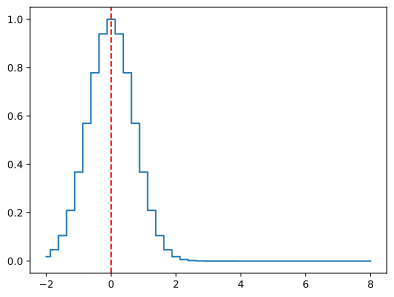

In [3]:
pyplot.step(x,advectee.get(),where='mid')
pyplot.axvline(0, color='r', linestyle='--')
show_plot('fig1')

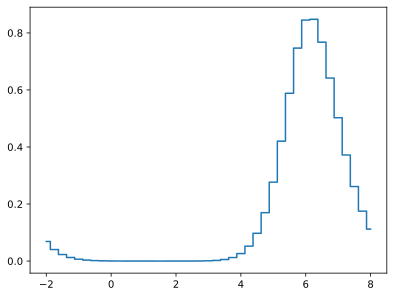

In [4]:
solver = Solver(
    advector=advector,
    advectee=advectee, 
    stepper=Stepper(n_dims=1,options=options))

solver.advance(n_steps=100)
pyplot.step(x,advectee.get(),where='mid')
show_plot('fig2')